# Put a field on a globe

**Atlas source reading copy · browser-network**

[Course guide](index.ipynb) · [Pinned original](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/0e32b2477ba5c0030985e25f1071d94cddabf130/content/17-globe.ipynb)



Browser-only piplite prepares numpy, matplotlib, pandas, xarray and ipywidgets. Calculations use earthlab.py and original synthetic arrays, not observations or real Digital Twin outputs. Optional widget controls need the source frontend; static figures and numerical results provide alternatives. Real DestinE accounts, Polytope/Data Lake services, GRIB/netCDF decoding and HPC remain explicit source/native continuations. No credentials or service requests are required for these defaults.

**Provenance:** `content/17-globe.ipynb` at `0e32b2477ba5c0030985e25f1071d94cddabf130`; original SHA-256 `22fcb269c9d65156c45e09afb9c906c8fd81feab571889379b73018d1441f323`. Original code MIT; original prose, generated numerical data and cleared artwork CC BY 4.0, with attribution and Atlas adaptation notice. Official DestinE references/datasets are linked context, not copied inputs.

**Verification:** imported by static inspection; saved upstream outputs cleared. Runtime compatibility is separate from executed verification. See the course guide for dependencies, excluded assets, aliases and original credits.


![Original abstract globe and synthetic weather streamlines](assets/splash.png)

# Put a field on a globe

**Lesson 17 · Original synthetic data · Independent educational project**

## Objectives

Transform spherical coordinates to Cartesian coordinates; verify radius.

[Previous](16-terrain.ipynb) · [Notebook source](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/content/17-globe.ipynb) · [Next](18-time.ipynb)

[Open this notebook in JupyterLite](https://jltobias.github.io/JupyterLite-Destination-Earth-Digital-Twin/lab/index.html?path=17-globe.ipynb) — public deployment pending until verified. For a local build, open the matching filename from the Lab file browser.

Run every code cell in order. The first run in JupyterLite downloads browser packages; it needs an internet connection. No account or credentials are used. The interactive visual lessons use ipywidgets, and the gallery provides additional live controls.

## Prepare the browser-sized environment

The shared `earthlab.py` helper lives beside every notebook. The same source notebook is used by the book and Lab.

In [1]:
import sys
if sys.platform == "emscripten":
    import piplite
    await piplite.install(["numpy", "matplotlib", "pandas", "xarray", "ipywidgets"])
import numpy as np
import matplotlib.pyplot as plt
import earthlab as lab
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print(lab.PROVENANCE)

Original synthetic teaching data; not observations or DestinE model output


## Worked experiment

Run this original experiment and inspect both its figure and numerical checks.

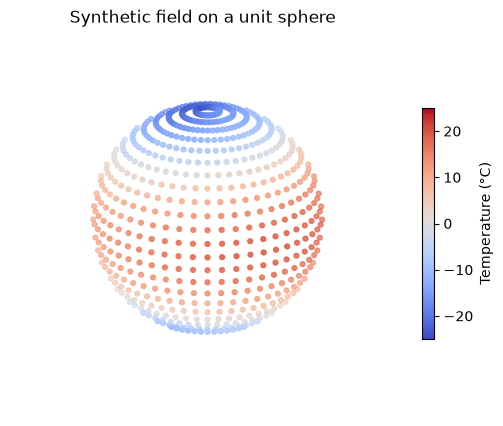

In [2]:
cube = lab.synthetic_cube(nlat=25, nlon=49)
lon, lat = np.meshgrid(cube["lon"], cube["lat"])
x, y, z = lab.globe_xyz(lat, lon)
assert np.allclose(x*x+y*y+z*z, 1)
field = cube["temperature"][0]-273.15
fig = plt.figure(figsize=(7, 5)); ax = fig.add_subplot(projection="3d")
elevation, azimuth = 20, -55
elev_rad, azim_rad = np.deg2rad([elevation, azimuth])
camera = np.array([np.cos(elev_rad)*np.cos(azim_rad), np.cos(elev_rad)*np.sin(azim_rad), np.sin(elev_rad)])
visible = x*camera[0] + y*camera[1] + z*camera[2] >= 0
assert 0 < visible.sum() < visible.size
points = ax.scatter(x[visible], y[visible], z[visible], c=field[visible], cmap="coolwarm", s=12, vmin=-25, vmax=25)
ax.set_proj_type("ortho"); ax.view_init(elev=elevation, azim=azimuth)
ax.set(xlim=(-1,1), ylim=(-1,1), zlim=(-1,1))
ax.set_box_aspect((1, 1, 1)); ax.set_axis_off()
ax.set_title("Synthetic field on a unit sphere")
fig.colorbar(points, ax=ax, shrink=.6, label="Temperature (°C)")
plt.show()

## Exercise

Use radius 2 and confirm every point is twice as far from the origin. Change the viewing longitude to inspect the hidden hemisphere.

Add a code cell with your modification and at least one assertion that would catch an incorrect result. Keep the original experiment as a reference.

## Interactive Lab experiment

Move the time slider, change the variable or rotate the 3D view. This widget runs in a Python kernel in Lab; the published book preserves a static output. Explain which control changes the data and which only changes its display.

In [ ]:
import ipywidgets as widgets
from IPython.display import display
interactive_cube = lab.synthetic_cube(nlat=19, nlon=31)
def explore(day=0, variable="temperature", azimuth=-55):
    units = interactive_cube["units"][variable]
    field = interactive_cube[variable][day]
    bounds = (245, 300) if variable == "temperature" else (0, 8)
    fig = plt.figure(figsize=(8, 4))
    ax = fig.add_subplot(projection="3d")
    lo, la = np.meshgrid(interactive_cube["lon"], interactive_cube["lat"])
    xx, yy, zz = lab.globe_xyz(la, lo)
    elev_rad, azim_rad = np.deg2rad([20, azimuth])
    camera = np.array([np.cos(elev_rad)*np.cos(azim_rad), np.cos(elev_rad)*np.sin(azim_rad), np.sin(elev_rad)])
    visible = xx*camera[0] + yy*camera[1] + zz*camera[2] >= 0
    im = ax.scatter(xx[visible], yy[visible], zz[visible], c=field[visible], cmap="viridis", s=15, vmin=bounds[0], vmax=bounds[1])
    ax.set_proj_type("ortho"); ax.set(xlim=(-1,1), ylim=(-1,1), zlim=(-1,1))
    ax.view_init(elev=20, azim=azimuth); ax.set_box_aspect((1,1,1))
    fig.colorbar(im, ax=ax, shrink=.6, label=units)
    fig.suptitle(f"Synthetic {variable}, day {day}")
    plt.tight_layout(); plt.show()
controls = widgets.interactive(explore, day=widgets.IntSlider(min=0,max=59,value=0),
                               variable=["temperature", "precipitation"], azimuth=(-180,180,5))
display(controls)

## Interpretation and limits

A globe avoids a flat-map seam in geometry but still hides a hemisphere. This spherical point rendering is not an ellipsoidal Earth model or a basemap.

**Check your reasoning:** identify one result the code establishes and one conclusion the demonstration cannot establish.

## References and provenance

- [Conceptual or software reference](https://destine.ecmwf.int/digital-twin-engine/) — linked for background; no text, external notebook code or data were copied.
- [Destination Earth initiative source index](https://github.com/destination-earth/DestinE).
- Generated arrays and equations: original project teaching material, CC BY 4.0; helper code: MIT. No authentic DestinE outputs or observational datasets are used.
- The abstract splash was generated for this project. See the repository's [attribution record](https://github.com/jltobias/JupyterLite-Destination-Earth-Digital-Twin/blob/main/ATTRIBUTIONS.md).